In [1]:
import sounddevice as sd
import numpy as np
import librosa
import time
import matplotlib.pyplot as plt

# Audio Settings
SAMPLE_RATE = 16000  # Standard speech recognition sample rate
SILENCE_THRESHOLD = 0.01  # Silence detection threshold (adjustable)
SILENCE_DURATION = 2  # Stop recording if sil

In [2]:
def record_audio_until_silence(sample_rate = SAMPLE_RATE, silence_threshold=SILENCE_THRESHOLD,silence_duration=SILENCE_DURATION):
    print("🎤 Listening... Speak now (Stops when silent for 3 seconds)...")
    
    audio_buffer = []
    silence_start = None
    stream = sd.InputStream(samplerate=sample_rate, channels=1,dtype=np.float32)
    
    with stream:
        while True:
            #Read audio chunk
            audio_chunk, _= stream.read(int(sample_rate*0.1)) #100ms chunks
            audio_buffer.append(audio_chunk)
            
            #Compute volume level
            volume_level = np.max(np.abs(audio_chunk))
            
            #Check for silence
            if volume_level < silence_threshold:
                if silence_start is None:
                    silence_start = time.time()
                    
                elif time.time() - silence_start >= silence_duration:
                    print("🛑 Silence detected! Stopping recording.")
                    break
                
            else:
                silence_start = None #Reset silence detection if user speaks    
         
    print(len(audio_buffer))     
    recorded_audio = np.concatenate(audio_buffer,axis=0).flatten()
    print(len(recorded_audio)) 
    
    print("✅ Recording complete.")
    return recorded_audio  # Return raw audio for next step        

    

🎤 Listening... Speak now (Stops when silent for 3 seconds)...
🛑 Silence detected! Stopping recording.
44
70400
✅ Recording complete.


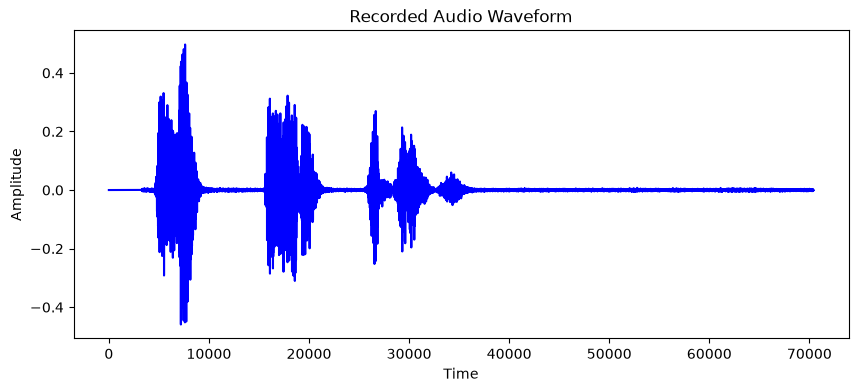

🔊 Playing recorded audio...


In [3]:
# Record audio with silence detection 
audio_data = record_audio_until_silence()

# Testing: Plot waveform of recorded audio
if audio_data is not None and len(audio_data) >0 :
    plt.figure(figsize=(10,4))
    plt.plot(audio_data, color="blue")
    plt.title("Recorded Audio Waveform")
    plt.xlabel("Time")
    plt.ylabel("Amplitude")
    plt.show()
    
    # 🔹 Optional: Listen to the recorded audio
    import soundfile as sf
    import io
    from IPython.display import Audio
    
    # Save to a buffer and play it
    wav_buffer = io.BytesIO()
    sf.write(wav_buffer, audio_data, SAMPLE_RATE, format="WAV")
    wav_buffer.seek(0)
    
    print("🔊 Playing recorded audio...")
    display(Audio(wav_buffer.read(), rate=SAMPLE_RATE))
    
    
else:
    print("⚠️ No audio recorded. Try speaking louder.")
        
    
    
    
    

Step 2: Convert Speech To Text

In [4]:
from transformers import WhisperProcessor, WhisperForConditionalGeneration

# Load Whisper processor & model from Hugging Face
stt_model_name = "openai/whisper-small"
stt_processor = WhisperProcessor.from_pretrained(stt_model_name)
stt_model = WhisperForConditionalGeneration.from_pretrained(stt_model_name)

# Ensure the model doesn't force a specific language
stt_model.config.forced_decoder_ids = None 

print("✅ Hugging Face Whisper Model Loaded Successfully")



d:\Document\NLP_Project\Audio_Classification\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 479/479 [00:00<00:00, 579.06it/s]


✅ Hugging Face Whisper Model Loaded Successfully


In [6]:
import soundfile as sf
import io
import torch

def transcribe_audio(audio_data, sample_rate=16000):
    print("⏳ Transcribing speech...")
    
    # Process the NumPy audio array directly (no need to convert to WAV)
    input_features = stt_processor(audio_data, sampling_rate=sample_rate, return_tensors="pt").input_features
    print("input_features: ",input_features)
    
    # Generate transcription
    with torch.no_grad():
        predicted_ids = stt_model.generate(input_features)
        print("predicted_ids: ",predicted_ids)
        
        
    # Decode token IDs into text
    transcription = stt_processor.batch_decode(predicted_ids, skip_special_tokens=True)[0]

    print(f"✅ Transcription: {transcription}")
    return transcription  # Return transcribed text

# Run transcription on recorded audio
transcribed_text = transcribe_audio(audio_data)
print("📝 Final Transcribed Text:", transcribed_text)    
        
    
    

⏳ Transcribing speech...


[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] Transcription using a multilingual Whisper will default to language detection followed by transcription instead of translation to English. This might be a breaking change for your use case. If you want to instead always translate your audio to English, make sure to pass `language='en'`. See https://github.com/huggingface/transformers/pull/28687 for more details.


input_features:  tensor([[[-0.7050, -0.7050, -0.7050,  ..., -0.7050, -0.7050, -0.7050],
         [-0.7050, -0.7050, -0.7050,  ..., -0.7050, -0.7050, -0.7050],
         [-0.7050, -0.7050, -0.7050,  ..., -0.7050, -0.7050, -0.7050],
         ...,
         [-0.7050, -0.7050, -0.7050,  ..., -0.7050, -0.7050, -0.7050],
         [-0.7050, -0.7050, -0.7050,  ..., -0.7050, -0.7050, -0.7050],
         [-0.7050, -0.7050, -0.7050,  ..., -0.7050, -0.7050, -0.7050]]])


[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


predicted_ids:  tensor([[2425,   11,  577,  366,  291,   30,  708,  366,  291,  884,   30]])
✅ Transcription:  Hello, how are you? What are you doing?
📝 Final Transcribed Text:  Hello, how are you? What are you doing?


Step 3: Classify the inyent based on user input

In [7]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

# Load the tokenizer and model
an_intent_model_name = "Serj/intent-classifier"
an_intent_tokenizer = AutoTokenizer.from_pretrained(an_intent_model_name)
an_intent_model = AutoModelForSeq2SeqLM.from_pretrained(an_intent_model_name)

print("✅ 'Serj/intent-classifier' Model Loaded Successfully!")



Loading weights: 100%|██████████| 282/282 [00:01<00:00, 239.08it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


✅ 'Serj/intent-classifier' Model Loaded Successfully!


In [10]:
# Few-shot examples provided in the prompt

few_shot_prompt = """\
Customer: I want to buy a new phone.
Intent: Shopping

Customer: How do I pay my electricity bill?
Intent: Bill Payment

Customer: My internet is not working properly.
Intent: Technical Issue

Customer: I need help resetting my bank password.
Intent: Customer Support

Customer: Can you recommend the best laptop for gaming?
Intent: Shopping

Customer: I was trying to make a payment, but I keep getting a 'Payment not authorized' error. 
Intent: Billing Issue

Customer: I received the wrong product and need to return it for a refund.
Intent: Returns & Refunds

Customer: My internet is not working properly and keeps disconnecting frequently.
Intent: Technical Issue

Customer: I am looking to upgrade my phone to the latest model and need advice on the best option.
Intent: Product Inquiry

Customer: I need help resetting my password for my online banking account.
Intent: Customer Support

Customer: I want to track my order that was supposed to be delivered yesterday.
Intent: Delivery / Order Tracking

Customer: I need to change my shipping address for an order I placed yesterday.
Intent: Order Modification

Customer: I am considering subscribing to your premium plan but want to understand the differences between the Basic and Premium plans.
Intent: Subscription Inquiry

Customer: {} 
Intent:"""

# 🔹 Function to Classify User Intent in Real-Time Using Few-Shot Learning
def classify_intent_few_shot(user_input):
    print("🔍 Classifying Intent...")

    # Format the input text with few-shot examples
    formatted_input = few_shot_prompt.format(user_input)
    
    # Tokenize the input
    inputs = an_intent_tokenizer(formatted_input,return_tensors="pt",max_length=512, truncation=True)
    print("Inputs: ",inputs)
    
    # Get model predictions
    with torch.no_grad():
        outputs = an_intent_model.generate(**inputs)
        print("outputs:" ,outputs)
        
    # Decode the generated response
    detected_intent = an_intent_tokenizer.decode(outputs[0], skip_special_tokens=True) 
    
    return detected_intent   
        
        
    

In [11]:
sample_text = """I was trying to purchase a laptop on your website, but when I added it to the cart and proceeded to payment, 
the system kept giving me an error saying 'Payment not authorized'. I tried two different credit cards, 
but I’m still facing the same issue. Can you please help me complete my order?"""

detected_intent = classify_intent_few_shot(sample_text)
print("🎯 Transcribed text:", sample_text)
print("🎯 Final Intent:", detected_intent)

🔍 Classifying Intent...
Inputs:  {'input_ids': tensor([[ 7327,    10,    27,   241,    12,   805,     3,     9,   126,   951,
             5,    86,  4669,    10, 14830,  7327,    10,   571,   103,    27,
           726,    82,  6373,  2876,    58,    86,  4669,    10,  3259, 12248,
          7327,    10,   499,  1396,    19,    59,   464,  3085,     5,    86,
          4669,    10, 10728, 13235,  7327,    10,    27,   174,   199,     3,
            60, 19966,    82,  2137,  4735,     5,    86,  4669,    10,  7327,
          4224,  7327,    10,  1072,    25,  1568,     8,   200,  4544,    21,
          7081,    58,    86,  4669,    10, 14830,  7327,    10,    27,    47,
          1119,    12,   143,     3,     9,  1942,     6,    68,    27,   453,
           652,     3,     9,     3,    31, 19702,   297,    59, 11330,    31,
          3505,     5,    86,  4669,    10,  3259,    53, 13235,  7327,    10,
            27,  1204,     8,  1786,   556,    11,   174,    12,  1205,    34,
     

d:\Document\NLP_Project\Audio_Classification\venv\Lib\site-packages\transformers\generation\utils.py:1805: UserWarning: Using the model-agnostic default `max_length` (=21) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


outputs: tensor([[    0,  5197, 19318,     1]])
🎯 Transcribed text: I was trying to purchase a laptop on your website, but when I added it to the cart and proceeded to payment, 
the system kept giving me an error saying 'Payment not authorized'. I tried two different credit cards, 
but I’m still facing the same issue. Can you please help me complete my order?
🎯 Final Intent: Order Status
